
=== GARCH(1,1) ===
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5057.55
Distribution:      Standardized Student's t   AIC:                           10125.1
Method:                  Maximum Likelihood   BIC:                           10154.6
                                              No. Observations:                 2699
Date:                      Tue, Sep 30 2025   Df Residuals:                     2698
Time:                              13:47:01   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-----------------------------------------------------------------

<Figure size 1400x600 with 0 Axes>

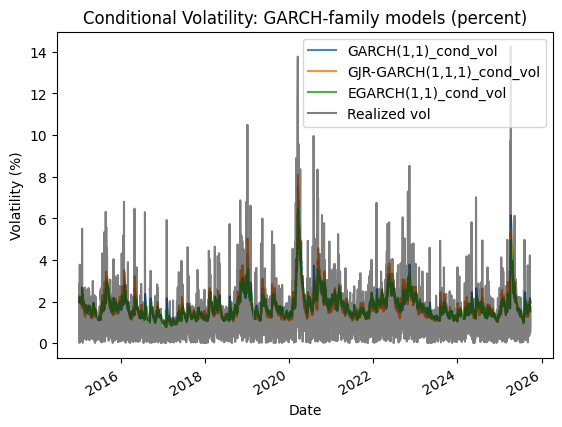


Evaluation (vs realized vol):
                      rmse       mae     n
model                                     
GJR-GARCH(1,1,1)  1.328948  1.029932  2699
EGARCH(1,1)       1.333880  1.039374  2699
GARCH(1,1)        1.343659  1.046216  2699

Saved rolling forecasts to ../data/processed/rolling_garch_forecasts.csv


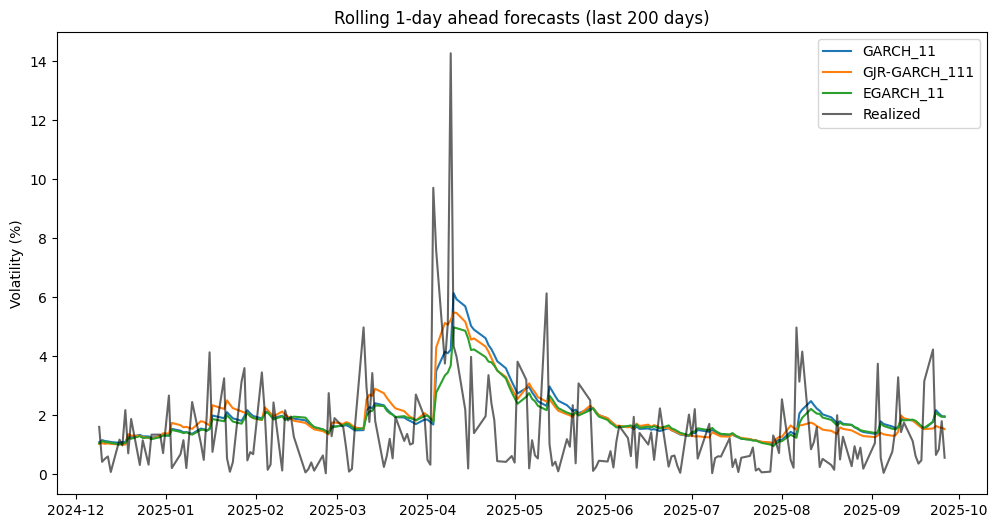


Diebold–Mariano test results (squared-error loss):
                                  DM_stat    pvalue
pair                                               
GARCH(1,1) vs GJR-GARCH(1,1,1)   1.290380  0.196919
GARCH(1,1) vs EGARCH(1,1)        1.468298  0.142023
GJR-GARCH(1,1,1) vs EGARCH(1,1) -0.178013  0.858713

Saved evaluation & comparison CSVs to ../data/processed/


In [3]:
# 03_garch_family_comparison.ipynb

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from arch import arch_model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# For Diebold-Mariano implementation
from statsmodels.tsa.stattools import acovf
from scipy import stats

# --- Utility: Diebold-Mariano test (basic implementation) ---
def diebold_mariano(e1, e2, h=1, alternative='two_sided'):
    """
    Diebold-Mariano test comparing loss series e1 and e2 (e.g., squared-error or QLIKE loss).
    e1, e2: arrays of same length with loss values for model1 and model2 (lower is better).
    h: forecast horizon (1 by default)
    Returns (DM_stat, pvalue)
    Notes: This is a simple implementation using Newey-West like long-run variance via acovf.
    """
    d = e1 - e2
    T = len(d)
    d_bar = d.mean()
    # lag selection: floor( T^(1/4) )
    L = int(np.floor(T ** (1/4)))
    # compute autocovariances
    acovs = acovf(d, fft=True, unbiased=True)[:L+1]  # acovf[0..L]
    # Newey-West long-run variance estimate
    weights = [1.0] + [1.0 - (k/(L+1)) for k in range(1, L+1)]
    s_hat = acovs[0] + 2 * sum(weights[k] * acovs[k] for k in range(1, L+1))
    dm_stat = d_bar / np.sqrt(s_hat / T)
    # two-sided or one-sided p-value
    if alternative == 'two_sided':
        pval = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    elif alternative == 'less':
        pval = stats.norm.cdf(dm_stat)
    else:
        pval = 1 - stats.norm.cdf(dm_stat)
    return dm_stat, pval

# --- 1. Load data ---
df = pd.read_csv("../data/processed/AAPL_processed.csv", parse_dates=["Date"])
df.set_index("Date", inplace=True)
returns = df["log_return"].dropna() * 100  # scale to percent (consistent with previous notebook)
realized_vol = np.sqrt(df["squared_return"].dropna()) * 100

# Keep aligned index where returns and realized_vol exist
common_idx = returns.dropna().index.intersection(realized_vol.index)
returns = returns.loc[common_idx]
realized_vol = realized_vol.loc[common_idx]

# --- 2. Fit GARCH-family models ---
models = {}
results = {}

# GARCH(1,1)
models['GARCH(1,1)'] = arch_model(returns, vol="Garch", p=1, q=1, mean='constant', dist='t')
results['GARCH(1,1)'] = models['GARCH(1,1)'].fit(disp='off')

# GJR-GARCH(1,1,1) -- asymmetric (o=1)
models['GJR-GARCH(1,1,1)'] = arch_model(returns, vol="Garch", p=1, o=1, q=1, mean='constant', dist='t')
results['GJR-GARCH(1,1,1)'] = models['GJR-GARCH(1,1,1)'].fit(disp='off')

# EGARCH(1,1)
models['EGARCH(1,1)'] = arch_model(returns, vol="EGARCH", p=1, q=1, mean='constant', dist='t')
results['EGARCH(1,1)'] = models['EGARCH(1,1)'].fit(disp='off')

# Print summaries
for name, res in results.items():
    print(f"\n=== {name} ===")
    print(res.summary())

# --- 3. Compare models (AIC/BIC/loglik) ---
compare_rows = []
for name, res in results.items():
    compare_rows.append({
        'model': name,
        'loglik': res.loglikelihood,
        'aic': res.aic,
        'bic': res.bic
    })
compare_df = pd.DataFrame(compare_rows).set_index('model').sort_values('aic')
print("\nModel comparison (by AIC):")
print(compare_df)

# --- 4. Extract conditional volatility series and align ---
for name, res in results.items():
    # conditional_volatility is in percent units (since we scaled returns)
    df[f"{name}_cond_vol"] = res.conditional_volatility.reindex(df.index)

# Also compute a realized_vol column aligned to df.index
df["realized_vol"] = np.sqrt(df["squared_return"]) * 100

# --- 5. Plot conditional volatilities vs realized ---
plt.figure(figsize=(14,6))
cols = [c for c in df.columns if c.endswith("_cond_vol")]
df[cols].dropna().plot(alpha=0.85)
plt.plot(df["realized_vol"].dropna().index, df["realized_vol"].dropna(), color='k', alpha=0.5, label='Realized vol')
plt.title("Conditional Volatility: GARCH-family models (percent)")
plt.ylabel("Volatility (%)")
plt.legend()
plt.show()

# --- 6. Evaluation: RMSE & MAE (using overlapping index where cond_vol & realized_vol available) ---
eval_rows = []
for name in results.keys():
    pred = df[f"{name}_cond_vol"].dropna()
    common = pred.index.intersection(df["realized_vol"].dropna().index)
    y_true = df.loc[common, "realized_vol"]
    y_pred = pred.loc[common]
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    eval_rows.append({'model': name, 'rmse': rmse, 'mae': mae, 'n': len(common)})
eval_df = pd.DataFrame(eval_rows).set_index('model').sort_values('rmse')
print("\nEvaluation (vs realized vol):")
print(eval_df)

# --- 7. Walk-forward 1-day ahead forecasts for each model (rolling re-estimation) ---
# We'll do a simpler rolling window: expanding window (train grows)
train_size = int(len(returns) * 0.8)
forecast_index = returns.index[train_size:]

rolling_forecasts = {name: [] for name in results.keys()}

for i in range(train_size, len(returns)):
    train = returns[:i]
    # Fit each model quickly (suppress output)
    # GARCH
    res_g = arch_model(train, vol="Garch", p=1, q=1, mean='constant', dist='t').fit(disp='off')
    f_g = res_g.forecast(horizon=1, reindex=False).variance.values[-1,0]
    rolling_forecasts['GARCH(1,1)'].append(np.sqrt(f_g))
    # GJR
    res_gjr = arch_model(train, vol="Garch", p=1, o=1, q=1, mean='constant', dist='t').fit(disp='off')
    f_gjr = res_gjr.forecast(horizon=1, reindex=False).variance.values[-1,0]
    rolling_forecasts['GJR-GARCH(1,1,1)'].append(np.sqrt(f_gjr))
    # EGARCH
    res_eg = arch_model(train, vol="EGARCH", p=1, q=1, mean='constant', dist='t').fit(disp='off')
    f_eg = res_eg.forecast(horizon=1, reindex=False).variance.values[-1,0]
    rolling_forecasts['EGARCH(1,1)'].append(np.sqrt(f_eg))

# Put rolling forecasts into a DataFrame
roll_df = pd.DataFrame(rolling_forecasts, index=forecast_index)
roll_df.columns = [c.replace("(", "_").replace(")", "").replace(",", "") for c in roll_df.columns]
roll_df.to_csv("../data/processed/rolling_garch_forecasts.csv", index=True)
print("\nSaved rolling forecasts to ../data/processed/rolling_garch_forecasts.csv")

# Plot rolling forecasts vs realized (last 100 points)
plt.figure(figsize=(12,6))
plot_slice = slice(-200, None)
for col in roll_df.columns:
    plt.plot(roll_df.index[plot_slice], roll_df[col].values[plot_slice], label=col)
plt.plot(df["realized_vol"].loc[roll_df.index][plot_slice].index,
         df["realized_vol"].loc[roll_df.index].values[plot_slice],
         label='Realized', color='k', alpha=0.6)
plt.legend()
plt.title("Rolling 1-day ahead forecasts (last 200 days)")
plt.ylabel("Volatility (%)")
plt.show()

# --- 8. Diebold-Mariano comparisons (on walk-forward forecasts) ---
# Use squared-error loss on vol forecasts as a simple loss function
dm_results = []
pairs = [('GARCH(1,1)', 'GJR-GARCH(1,1,1)'),
         ('GARCH(1,1)', 'EGARCH(1,1)'),
         ('GJR-GARCH(1,1,1)', 'EGARCH(1,1)')]

# align realized to roll_df index
real_for_roll = df["realized_vol"].loc[roll_df.index]

for m1, m2 in pairs:
    col1 = m1.replace("(", "_").replace(")", "").replace(",", "")
    col2 = m2.replace("(", "_").replace(")", "").replace(",", "")
    e1 = (real_for_roll - roll_df[col1])**2
    e2 = (real_for_roll - roll_df[col2])**2
    dm_stat, pval = diebold_mariano(e1.values, e2.values, h=1)
    dm_results.append({'pair': f"{m1} vs {m2}", 'DM_stat': dm_stat, 'pvalue': pval})

dm_df = pd.DataFrame(dm_results).set_index('pair')
print("\nDiebold–Mariano test results (squared-error loss):")
print(dm_df)

# --- 9. Save summary results ---
eval_df.to_csv("../data/processed/garch_model_eval_summary.csv")
compare_df.to_csv("../data/processed/garch_model_compare.csv")
dm_df.to_csv("../data/processed/garch_diebold_mariano.csv")
print("\nSaved evaluation & comparison CSVs to ../data/processed/")
